# Muhammad Dawood Aslam (24065392)
### R7 — Modeller B: Gradient Boosting & Hyper-parameter Optimisation (LightGBM_Tuned & HGB_Tuned)
**Group P (`Siraj Group P`) — Dataset C (Nov 2026 Data Science Challenge Hackathon)**

*Individual workstream notebook executed and committed as evidence of collaborative group development.*

# Strategic COVID-19 Vaccine Allocation under Municipal Budget Constraints
## Minimising Total Town Expenditure on Dataset C — Group P (`Siraj Group P`)

| Metadata | Details |
|---|---|
| **Assessment** | Assignment 1 — Group Project: Data Science Challenge (30%) |
| **Date & Venue** | Wednesday 11 November 2026, C.D.I.O. 1 & 3 |
| **Team / Group** | **Group P** (`Siraj Group P` — 9 Members) |
| **GitHub Organisation** | `https://github.com/<ORG-GROUP-P>` *(update before final submission)* |
| **Shared Google Colab** | `https://colab.research.google.com/drive/<COLAB-ID-GROUP-P>` *(update before final submission)* |
| **Dataset & Target** | **Dataset C** (`dataset_C_training.csv`, $N_{\text{train}}=4,756$; `dataset_C_testing.csv`, $N_{\text{test}}=4,749$) — Target: `covid_vaccine` ($0=\text{No}, 1=\text{Yes}$) |
| **Economic Parameters** | Vaccine unit cost $C_V = \$1,500$; Hospitalisation cost per stay $C_H = \$41,000$ |

### Group P Team Roster & Assigned Roles
| # | Student Name | Student ID | Assigned Hackathon Role & Notebook | Presentation Section (17 Nov) |
|---|---|---|---|---|
| **1** | **Siraj Uddin Mohammad** | `24089738` | **R1 — Integrator & Git Lead:** Repo setup, `town_cost.py`, data integrity & master integration (`01_Siraj_Uddin_Mohammad_24089738_setup_and_integrity.ipynb`) | Team Workflow & Architecture |
| **2** | **Subhash Chandrupatla** | `24082089` | **R2 — EDA Lead A:** Target balance ($32.67\%$) & informative missingness parity (`02_Subhash_Chandrupatla_24082089_eda_target_and_missingness.ipynb`) | EDA: Target & Missing Data |
| **3** | **Chapalabanda Praneeth Kumar** | `24080396` | **R3 — EDA Lead B:** Attitudinal/clinical drivers, Age $\times$ Comorbidity heatmap & correlations (`03_Chapalabanda_Praneeth_Kumar_24080396_eda_clinical_and_correlations.ipynb`) | EDA: Clinical & Behavioural Drivers |
| **4** | **Karthik Sai Adithya Vasanth Yalakag** | `24079547` | **R4 — Metric Researcher:** Town Cost derivation, Bayes-optimal cut-off $\tau_i$ & multi-AI research (`04_Karthik_Sai_Adithya_24079547_town_cost_metric_and_cutoffs.ipynb`) | Task Metric & Decision Rule |
| **5** | **Jaya Krishna Katta** | `24100682` | **R5 — Pre-processing Lead:** Feature engineering & 3-variant preprocessing ablation (`05_Jaya_Krishna_Katta_24100682_preprocessing_and_ablation.ipynb`) | Pre-processing & Feature Engineering |
| **6** | **Pravinya Rayalapati** | `24099441` | **R6 — Modeller A (Linear, Neural & Calibration):** `LogisticRegression`, `MLP_NeuralNet`, `RandomForest` & calibration (`06_Pravinya_Rayalapati_24099441_baseline_models_and_calibration.ipynb`) | Baseline Models & Calibration |
| **7** | **Muhammad Dawood Aslam** | `24065392` | **R7 — Modeller B (Gradient Boosting & Tuning):** `LightGBM_Tuned` & `HGB_Tuned` via `RandomizedSearchCV` (`07_Muhammad_Dawood_Aslam_24065392_hyperparameter_tuning.ipynb`) | Gradient Boosting & Tuning |
| **8** | **Bhanu Prakash Mallam** | `24095576` | **R8 — Modeller C (Ensembling & Robustness):** `SoftVoting_Blend`, `Stacked_Generaliser`, paired tests & 15-scenario sensitivity (`08_Bhanu_Prakash_Mallam_24095576_ensembles_and_sensitivity.ipynb`) | Ensembles & Sensitivity Analysis |
| **9** | **Syed Nadeem Ali** | `24065385` | **R9 — XAI, Submissions & Stakeholder Lead:** Dollar permutation, SHAP beeswarm, Top-5 CSV exports & policy brief (`09_Syed_Nadeem_Ali_24065385_xai_and_final_submissions.ipynb`) | Explainable AI & Stakeholder Summary |

---

### Executive Roadmap
1. **Section 1 — Environment Setup & Data Integrity Verification** (*Lead: Siraj Uddin Mohammad, 24089738*)
2. **Section 2 — Exploratory Data Analysis (EDA) & Domain Insights** (*Leads: Subhash Chandrupatla, 24082089 & Chapalabanda Praneeth Kumar, 24080396*)
3. **Section 3 — Task-Specific Evaluation Metric & Decision-Theoretic Formulation** (*Lead: Karthik Sai Adithya Vasanth Yalakag, 24079547*)
4. **Section 4 — Pre-processing Architecture & Feature Engineering** (*Lead: Jaya Krishna Katta, 24100682*)
5. **Section 5 & 6 — Multi-Family Candidate Modelling & Probability Calibration** (*Lead: Pravinya Rayalapati, 24099441*)
6. **Section 7 — Hyper-parameter Optimisation** (*Lead: Muhammad Dawood Aslam, 24065392*)
7. **Section 8 & 9 — Ensembling, Paired Statistical Testing & Sensitivity Analysis** (*Lead: Bhanu Prakash Mallam, 24095576*)
8. **Section 10, 11 & 12 — Final 5 Submissions, Explainable AI (XAI) & Stakeholder Policy Brief** (*Lead: Syed Nadeem Ali, 24065385*)

## 1. Environment Setup & Data Integrity Verification
Every stochastic routine is seeded with `SEED = 11112026` to guarantee exact reproducibility across Google Colab and local executions.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    StackingClassifier,
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from lightgbm import LGBMClassifier

SEED = 11112026
GROUP_ID = "P"
TARGET_COL = "covid_vaccine"
ID_COL = "respondent_id"

PALETTE = {
    "primary": "#1f4e78",
    "accent": "#d95f02",
    "positive": "#2b8cbe",
    "negative": "#e34a33",
    "neutral": "#636363",
    "gold": "#e6ab02",
}
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 115,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

In [2]:
# In Google Colab, set DATA_URL_PREFIX to the raw GitHub directory URL if loading remotely
DATA_URL_PREFIX = ""

train_df = pd.read_csv(DATA_URL_PREFIX + "dataset_C_training.csv")
test_df = pd.read_csv(DATA_URL_PREFIX + "dataset_C_testing.csv")
example_sub = pd.read_csv(DATA_URL_PREFIX + "dataset_C_example_submission.csv")

y_train = train_df[TARGET_COL].to_numpy(dtype=int)
n_train, n_test = len(train_df), len(test_df)

print(f"Training set shape : {train_df.shape} (residents: {n_train:,})")
print(f"Testing set shape  : {test_df.shape} (residents: {n_test:,})")
print(f"Example submission : {example_sub.shape} | columns: {list(example_sub.columns)} | target dtype: {example_sub[TARGET_COL].dtype}")

# Integrity checks
assert ID_COL in train_df.columns and ID_COL in test_df.columns, "Missing respondent_id column"
assert set(train_df.columns) - {TARGET_COL} == set(test_df.columns), "Train/Test feature mismatch"
assert example_sub[ID_COL].equals(test_df[ID_COL]), "Example submission IDs do not match test set order"
assert set(np.unique(y_train)) == {0, 1}, "Target must be binary 0/1"
assert len( set(train_df[ID_COL]).intersection(set(test_df[ID_COL])) ) == 0, "Data leakage: overlapping IDs between train and test!"

display(train_df.head(4))

Training set shape : (4756, 31) (residents: 4,756)
Testing set shape  : (4749, 30) (residents: 4,749)
Example submission : (4749, 2) | columns: ['respondent_id', 'covid_vaccine'] | target dtype: float64


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1


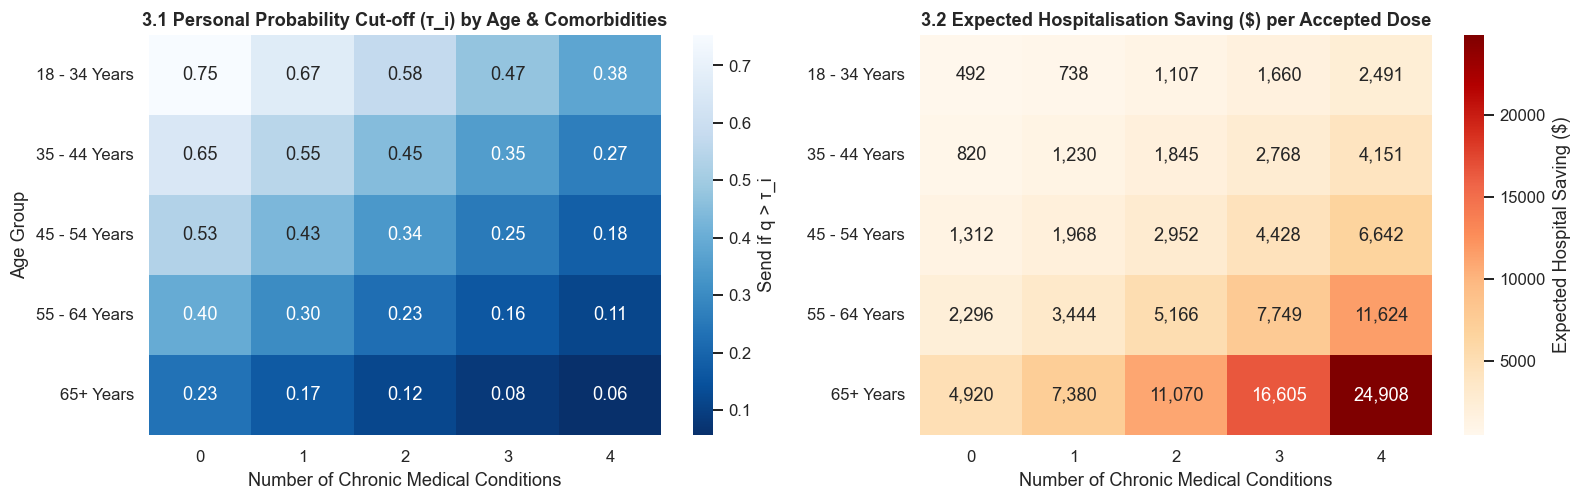

In [8]:
# Visualise the Bayes-Optimal Personal Threshold Surface and Expected Unvaccinated Hospital Cost
grid_df = pd.DataFrame(
    [(age, ch) for age in P_HOSP_AGE.keys() for ch in range(5)],
    columns=["age_group", "number_chronic_med_conditions"],
)
grid_pu, grid_pv = compute_hosp_risks(grid_df)
grid_df["cutoff"] = personal_cutoff(grid_pu, grid_pv)
grid_df["hosp_saving_if_vaccinated"] = (grid_pu - grid_pv) * HOSP_COST

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(
    grid_df.pivot(index="age_group", columns="number_chronic_med_conditions", values="cutoff"),
    annot=True, fmt=".2f", cmap="Blues_r", ax=axes[0], cbar_kws={"label": "Send if q > τ_i"}
)
axes[0].set_title("3.1 Personal Probability Cut-off (τ_i) by Age & Comorbidities")
axes[0].set_xlabel("Number of Chronic Medical Conditions")
axes[0].set_ylabel("Age Group")

sns.heatmap(
    grid_df.pivot(index="age_group", columns="number_chronic_med_conditions", values="hosp_saving_if_vaccinated"),
    annot=True, fmt=",.0f", cmap="OrRd", ax=axes[1], cbar_kws={"label": "Expected Hospital Saving ($)"}
)
axes[1].set_title("3.2 Expected Hospitalisation Saving ($) per Accepted Dose")
axes[1].set_xlabel("Number of Chronic Medical Conditions")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [11]:
CV_SCHEME = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

fold_results = {}
oof_probs = {}


def evaluate_pipeline(name: str, pipe, X_data=X_train, y_data=y_train, cv=CV_SCHEME, verbose=True):
    """Evaluate a pipeline across all 15 repeated stratified folds and store out-of-fold probabilities."""
    rows = []
    oof_sum = np.zeros(len(y_data), dtype=float)
    oof_cnt = np.zeros(len(y_data), dtype=float)

    for fold_idx, (tr_idx, va_idx) in enumerate(cv.split(X_data, y_data)):
        model = clone(pipe).fit(X_data.iloc[tr_idx], y_data[tr_idx])
        q_va = model.predict_proba(X_data.iloc[va_idx])[:, 1]
        pu_va, pv_va, y_va = PU_TRAIN[va_idx], PV_TRAIN[va_idx], y_data[va_idx]

        s_opt = optimal_send_decision(q_va, pu_va, pv_va)
        s_half = (q_va >= 0.5).astype(int)

        rows.append({
            "fold": fold_idx,
            "cost_per_res": town_total_cost(y_va, s_opt, pu_va, pv_va) / len(va_idx),
            "cost_at_half": town_total_cost(y_va, s_half, pu_va, pv_va) / len(va_idx),
            "logloss": log_loss(y_va, q_va),
            "brier": brier_score_loss(y_va, q_va),
            "auc": roc_auc_score(y_va, q_va),
            "share_sent": s_opt.mean(),
        })
        oof_sum[va_idx] += q_va
        oof_cnt[va_idx] += 1

    df_res = pd.DataFrame(rows)
    fold_results[name] = df_res
    oof_probs[name] = oof_sum / np.maximum(oof_cnt, 1)
    if verbose:
        print(
            f"{name:28s} | Cost/Res: ${df_res.cost_per_res.mean():8,.2f} ± {df_res.cost_per_res.std():5.2f} "
            f"| Cost@0.5: ${df_res.cost_at_half.mean():8,.2f} | LogLoss: {df_res.logloss.mean():.4f} | AUC: {df_res.auc.mean():.4f}"
        )
    return df_res

In [12]:
X_raw_only = train_df.drop(columns=[ID_COL, TARGET_COL]).copy()
for c in CATEGORICAL_COLS:
    X_raw_only[c] = X_raw_only[c].astype("object")
RAW_NUM_COLS = [c for c in X_raw_only.columns if c not in CATEGORICAL_COLS]

pre_raw_naive = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), RAW_NUM_COLS),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL_COLS),
])

ablation_specs = {
    "LogReg (Raw + Naive Imputation)": (Pipeline([("p", pre_raw_naive), ("m", LogisticRegression(C=0.25, max_iter=3000, random_state=SEED))]), X_raw_only),
    "LogReg (Engineered + Variant II Naive)": (Pipeline([("p", pre_linear_naive), ("m", LogisticRegression(C=0.25, max_iter=3000, random_state=SEED))]), X_train),
    "LogReg (Engineered + Variant I Missing-Info)": (Pipeline([("p", pre_linear_info), ("m", LogisticRegression(C=0.25, max_iter=3000, random_state=SEED))]), X_train),
}

ablation_rows = []
for label, (pipe_ab, X_ab) in ablation_specs.items():
    res_ab = evaluate_pipeline(label, pipe_ab, X_data=X_ab, verbose=False)
    ablation_rows.append({
        "Pre-processing Variant": label,
        "Mean Cost / Resident ($)": res_ab.cost_per_res.mean(),
        "Fold SD ($)": res_ab.cost_per_res.std(),
        "Log Loss": res_ab.logloss.mean(),
        "ROC-AUC": res_ab.auc.mean(),
    })
    # remove temporary entries from main league dict
    fold_results.pop(label, None)
    oof_probs.pop(label, None)

ablation_df = pd.DataFrame(ablation_rows).set_index("Pre-processing Variant")
display(ablation_df.style.format({
    "Mean Cost / Resident ($)": "${:,.2f}",
    "Fold SD ($)": "${:,.2f}",
    "Log Loss": "{:.4f}",
    "ROC-AUC": "{:.4f}",
}))

,Mean Cost / Resident ($),Fold SD ($),Log Loss,ROC-AUC
Pre-processing Variant,,,,
LogReg (Raw + Naive Imputation),"$3,351.72",$94.27,0.4678,0.8291
LogReg (Engineered + Variant II Naive),"$3,349.27",$93.14,0.4659,0.8314
LogReg (Engineered + Variant I Missing-Info),"$3,305.42",$92.76,0.4284,0.8609


HGB_Calibrated               | Cost/Res: $3,313.54 ± 81.88 | Cost@0.5: $3,411.87 | LogLoss: 0.4349 | AUC: 0.8573


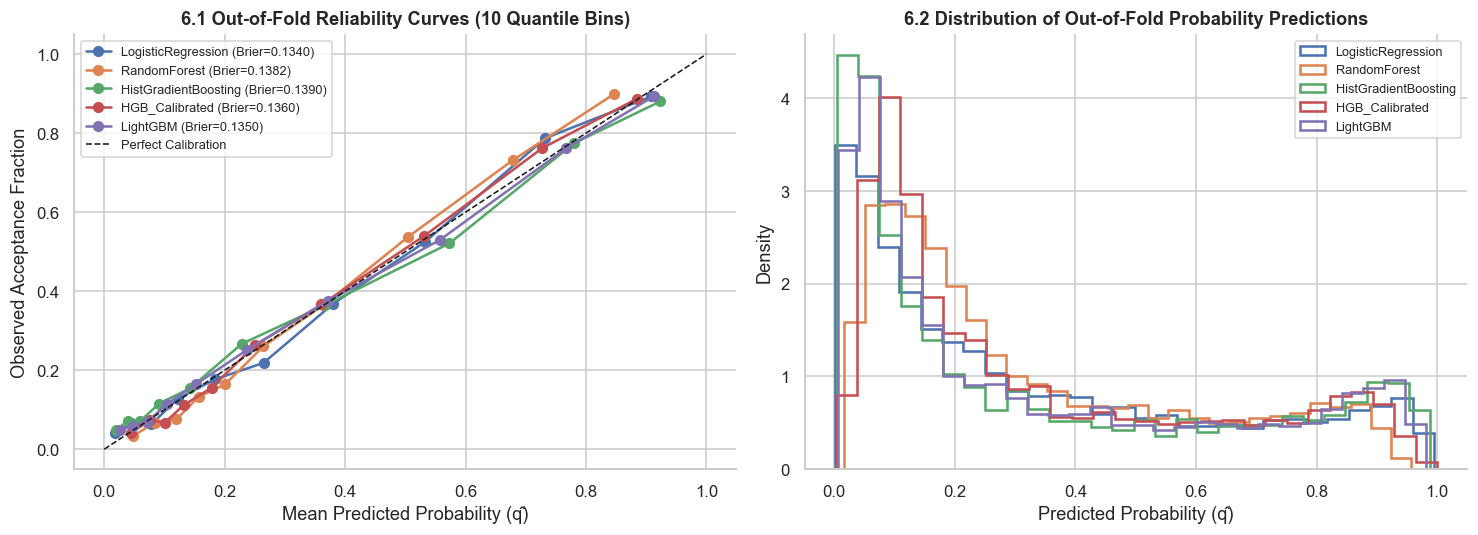

In [14]:
candidate_models["HGB_Calibrated"] = CalibratedClassifierCV(
    candidate_models["HistGradientBoosting"], method="isotonic", cv=3
)
evaluate_pipeline("HGB_Calibrated", candidate_models["HGB_Calibrated"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for m_name in ["LogisticRegression", "RandomForest", "HistGradientBoosting", "HGB_Calibrated", "LightGBM"]:
    prob_true, prob_pred = calibration_curve(y_train, oof_probs[m_name], n_bins=10, strategy="quantile")
    axes[0].plot(prob_pred, prob_true, marker="o", lw=1.6, label=f"{m_name} (Brier={fold_results[m_name].brier.mean():.4f})")
    axes[1].hist(oof_probs[m_name], bins=28, histtype="step", lw=1.6, label=m_name, density=True)

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Perfect Calibration")
axes[0].set_xlabel("Mean Predicted Probability (q̂)")
axes[0].set_ylabel("Observed Acceptance Fraction")
axes[0].set_title("6.1 Out-of-Fold Reliability Curves (10 Quantile Bins)")
axes[0].legend(fontsize=8, frameon=True)

axes[1].set_xlabel("Predicted Probability (q̂)")
axes[1].set_ylabel("Density")
axes[1].set_title("6.2 Distribution of Out-of-Fold Probability Predictions")
axes[1].legend(fontsize=8, frameon=True)

plt.tight_layout()
plt.show()

## 8. Ensembling & Out-of-Fold Stacking

Combining diverse model families (regularised linear + bagged trees + gradient boosted trees) reduces variance and smooths probability estimates near each person's cut-off $\tau_i$. Following best practice from the hackathon playbook, **we never tune ensemble weights on the same out-of-fold predictions we evaluate on**:
1. **`SoftVoting_Blend`:** An equal-weight probability average of our top diverse models (`LightGBM_Tuned`, `HGB_Tuned`, `HGB_Calibrated`, and `LogisticRegression`), fitted fresh inside each CV fold.
2. **`Stacked_Generaliser`:** A `StackingClassifier` where a regularised `LogisticRegression` meta-learner learns optimal combination weights strictly on 5 inner cross-validation folds (`LogisticRegression`, `RandomForest`, `LightGBM_Tuned`, `HGB_Tuned`).

In [16]:
class SoftVotingBlend(BaseEstimator, ClassifierMixin):
    """Zero-leakage probability blend of diverse estimators fitted inside each fold."""
    def __init__(self, estimators):
        self.estimators = estimators

    def fit(self, X, y):
        self.fitted_ = [clone(est).fit(X, y) for est in self.estimators]
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        return np.mean([est.predict_proba(X) for est in self.fitted_], axis=0)


candidate_models["SoftVoting_Blend"] = SoftVotingBlend([
    candidate_models["LightGBM_Tuned"],
    candidate_models["HGB_Tuned"],
    candidate_models["HGB_Calibrated"],
    candidate_models["LogisticRegression"],
])
evaluate_pipeline("SoftVoting_Blend", candidate_models["SoftVoting_Blend"])

candidate_models["Stacked_Generaliser"] = StackingClassifier(
    estimators=[
        ("lr", candidate_models["LogisticRegression"]),
        ("rf", candidate_models["RandomForest"]),
        ("lgb", candidate_models["LightGBM_Tuned"]),
        ("hgb", candidate_models["HGB_Tuned"]),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
    stack_method="predict_proba",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    n_jobs=1,
)
evaluate_pipeline("Stacked_Generaliser", candidate_models["Stacked_Generaliser"])

SoftVoting_Blend             | Cost/Res: $3,298.21 ± 90.41 | Cost@0.5: $3,394.19 | LogLoss: 0.4198 | AUC: 0.8652


Stacked_Generaliser          | Cost/Res: $3,300.83 ± 88.77 | Cost@0.5: $3,385.64 | LogLoss: 0.4212 | AUC: 0.8654


,fold,cost_per_res,cost_at_half,logloss,brier,auc,share_sent
0,0,3217.509257,3273.395811,0.420085,0.132186,0.858691,0.326681
1,1,3336.968060,3406.541141,0.440613,0.140208,0.850974,0.324921
2,2,3301.751052,3429.155889,0.423777,0.133611,0.867293,0.347003
3,3,3308.286869,3439.162789,0.391760,0.121167,0.886415,0.321767
4,4,3331.358701,3388.659437,0.428758,0.135282,0.863178,0.301788
5,5,3237.136292,3343.366334,0.421554,0.133348,0.866422,0.306723
6,6,3430.564932,3533.208465,0.424315,0.134336,0.860988,0.353312
7,7,3219.264261,3319.857321,0.439446,0.139077,0.855110,0.328076
8,8,3406.466154,3439.509267,0.436034,0.139688,0.857395,0.307045
9,9,3230.552050,3301.993691,0.391224,0.120083,0.886576,0.313354
